# Structure-preserving models for AMM dynamics

**Compact research notebook — a compact new experimental protocol.** All experiment code is visible here; the notebook has no imports from the project package. Open in Colab and run top to bottom. The original repository remains the development and historical-evidence archive.

This notebook tests three questions: (1) do mechanism transitions preserve their stated structural properties, (2) when does history predict flow beyond simple baselines, and (3) does source training help at equal target-data budgets after shrinkage controls? A positive forecasting result is an outcome to test, rather than an assumption.

**Important version boundary:** this is a new, smaller implementation. It uses input-reserve-normalized CPMM flow, actual fee-in-reserve accounting, library estimators, and a deliberately small synthetic generator. Its numbers must not be represented as reruns of the repository's older tables. Freeze the final protocol before inspecting final test performance. Synthetic and real-study code is present. The execution status, dataset card, hashes and exported tables below determine whether a run includes actual market evidence. The companion preparation notebook acquires, reconciles and normalizes the source data.


## 1. Mechanisms and the structural claim

For CPMM reserves $x,y>0$, price is $p=y/x$. Let signed flow $u$ be the **gross input divided by the input token's pre-trade reserve**, positive for token B input. For $u\geq0$, $y'=y(1+u)$ and $x'=x/[1+(1-f)u]$; the opposite direction exchanges the roles of $x,y$. Thus $x'y'=xy$ at zero fee and $x'y'\geq xy$ with fees retained in reserves. The reserve-ratio spot-price maps $p=y/x$ and $1/p=x/y$ are reciprocal. Fee-inclusive executable buy/sell quotes include a spread and are not reciprocal.

For binary LMSR, $r=(q_1-q_0)/b$, $p_1=\operatorname{sigmoid}(r)$, and $p_0=1-p_1$. Here $u$ denotes the change in log odds; the compact simulator implements a purchase on the corresponding outcome. It is not a model of trader inventory or an empirical test of sell admissibility.

**Proposition:** finite admissible generated flow, a correct transition, and its corresponding price map preserve these properties at every finite step in exact arithmetic, by applying the one-step identities inductively. Numerical overflow and probability saturation must still be measured. This property belongs to the transition and is shared by all flow estimators using it; it does not establish superior learned forecasting.

**Error propagation:** the CPMM log-price increment is $g_f(u)=\operatorname{sign}(u)[\log(1+|u|)+\log(1+(1-f)|u|)]$. Its absolute derivative is at most $2-f$, including across zero by continuity. From the same origin, $|s'(u)-s'(v)|\leq(2-f)|u-v|$. The LMSR log-odds error is exactly $|u-v|$. This elementary bound explains how flow error becomes price-coordinate error; for unnormalized gross amounts, sensitivity also includes the inverse input reserve. It is not presented as a novel theorem.

Fee accounting follows the [Uniswap v2 pair contract](https://github.com/Uniswap/v2-core/blob/master/contracts/UniswapV2Pair.sol). This synthetic model omits integer rounding and nonstandard swaps; those require reconciliation in the real study.


In [1]:
import math

def transition(mechanism, state, u, fee=0.003, b=100.0):
    a, c = state
    if mechanism == "CPMM":
        return ((a / (1 + (1-fee)*u), c*(1+u)) if u >= 0 else
                (a*(1-u), c / (1-(1-fee)*u)))
    return (a + b*max(-u, 0), c + b*max(u, 0))

def coordinate(mechanism, state, b=100.0):
    return math.log(state[1] / state[0]) if mechanism == "CPMM" else (state[1]-state[0])/b

def structural_checks(mechanism, before, after, fee=0.003, b=100.0):
    finite = all(math.isfinite(v) for v in after)
    if mechanism == "CPMM":
        valid = finite and min(after) > 0
        k0, k1 = math.prod(before), math.prod(after)
        return valid and (k1 >= k0*(1-1e-10) if fee else math.isclose(k0, k1, rel_tol=1e-10))
    r = coordinate(mechanism, after, b)
    p = 1/(1+math.exp(-max(-700, min(700, r))))
    return finite and 0 < p < 1

for fee in (0.0, 0.003):
    for u in (-0.4, -0.01, 0.0, 0.2):
        for mechanism, state in (("CPMM", (100., 150.)), ("LMSR", (0., 0.))):
            after = transition(mechanism, state, u, fee)
            assert structural_checks(mechanism, state, after, fee)
    for u in (-0.4, -0.01, 0.0, 0.2):
        for v in (-0.3, 0.0, 0.5):
            a = coordinate("CPMM", transition("CPMM", (100., 150.), u, fee))
            c = coordinate("CPMM", transition("CPMM", (100., 150.), v, fee))
            assert abs(a-c) <= (2-fee)*abs(u-v)+1e-12
print("One-step structural identity checks passed.")


One-step structural identity checks passed.


## 2. Setup and the frozen experiment budget

Colab normally supplies the libraries below. In another environment install `numpy pandas matplotlib scipy scikit-learn torch`. The final profile is the default: ten target markets and three source repeats with the same small models. The demo profile checks execution. Neither profile automatically constitutes final evidence. Record protocol changes and choose final source/market seeds before the definitive run. `protocol.json` is written before fitting; the manifest records its hash and the executed-code hash. No GPU is required.


In [2]:
import copy, hashlib, importlib.metadata, json, platform, os, random, statistics
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn
from IPython.display import display

PROFILE = os.environ.get("AMM_PROFILE", "final")                       # Freeze a final run before using its results.
CFG = {"demo": dict(steps=96, markets=3, seeds=[101], draws=40, epochs=50),
       "final": dict(steps=192, markets=10, seeds=[101, 211, 307], draws=200, epochs=150)}[PROFILE]
LOOKBACK, FLOW_LIMIT, HORIZONS = 4, 1.0, (10, 50)
OUT = Path(os.environ.get("AMM_OUTPUT_ROOT", "notebook_results")) / PROFILE
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
print(PROFILE, CFG)

DATA_DIR = Path(os.environ.get("AMM_DATA_DIR", "real_data/uniswap_v2_usdc_weth_2024_8weeks"))
BOOTSTRAP_REPEATS, CALENDAR_BLOCK_DAYS = 1000, 3
REAL_FIT_CAP, REAL_VALIDATION_CAP, REAL_EPOCHS = 4096, 2048, 50

FROZEN_PROTOCOL = dict(profile=PROFILE, config=CFG, mechanisms=["CPMM","LMSR"],
    scenarios=["null_noise","nonlinear","reference"], lookback=LOOKBACK, flow_limit=FLOW_LIMIT, horizons=HORIZONS,
    adaptation_budgets=[0.,.1,.25,.5], target_market_seeds=list(range(10000,10000+CFG["markets"])),
    adaptation_market_seeds=list(range(20000,20000+CFG["markets"])),
    primary_flow_contrast="MLP minus ridge within each mechanism/scenario",
    primary_adaptation_contrast="source MLP plus bias minus shrinkage mean",
    primary_path_contrast="MLP minus ridge terminal CRPS within each mechanism/horizon",
    reference_rollout="frozen at origin", tail_rule="95th percentile absolute validation return times sqrt(horizon)",
    normalizer="gross input/input-token reserve for CPMM; log-odds change for LMSR",
    models=dict(mlp_hidden=16,gru_hidden=12,mlp_max_iter=300),
    real_compute=dict(fit_cap=REAL_FIT_CAP,validation_cap=REAL_VALIDATION_CAP,gru_epochs=REAL_EPOCHS,
                      sampling="evenly spaced chronological observations; identical across models"),
    uncertainty="paired target markets; source repeats averaged within market; descriptive intervals")
(OUT/"protocol.json").write_text(json.dumps(FROZEN_PROTOCOL,indent=2))


final {'steps': 192, 'markets': 10, 'seeds': [101, 211, 307], 'draws': 200, 'epochs': 150}


1542

## 3. History-only data and a deliberately small synthetic benchmark

Every row forecasts the next event. Features contain two lagged flows, a four-event flow mean and standard deviation, an already-observed reference-price gap/return, and a mechanism indicator. Estimators receive the same four-row history. No next trade, post-trade state, or next arrival time enters the features.

The null is conditionally mean-zero flow. The nonlinear generator explicitly plants predictable flow. The reference generator explicitly plants externally observable signal. These are diagnostics, not claims that real markets follow these equations. The lower-depth target also changes normalized noise amplitude, so its result describes a combined depth/flow shift rather than an isolated causal liquidity effect. Flow is clipped by a declared generator rule, and every model shares the same prediction limit.

The exported scenario is named `null_noise` so CSV readers do not interpret its label as a missing value.


In [3]:
def features(mechanism, state, history, reference, reference_return, b):
    lag = ([0.0]*4 + list(history))[-4:]
    return [lag[-1], lag[-2], np.mean(lag), np.std(lag),
            reference-coordinate(mechanism, state, b), reference_return, float(mechanism == "LMSR")]

def make_path(mechanism, regime, seed, depth=1000.0):
    rng = np.random.default_rng(seed)
    b, fee = depth/10, 0.003
    states = [(depth, depth)] if mechanism == "CPMM" else [(0., 0.)]
    flow, refs, ref_returns = [], [], []
    reference, previous_return = 0., 0.
    for _ in range(CFG["steps"]):
        reference_return = 0.2*previous_return + rng.normal(0, 0.02)
        reference += reference_return             # Observed at this forecast origin.
        last = flow[-1] if flow else 0.
        gap = reference-coordinate(mechanism, states[-1], b)
        signal = (0.055*np.tanh(25*last) if regime == "nonlinear" else
                  0.3*last + 0.045*np.tanh(12*gap) + 0.5*reference_return if regime == "reference" else 0.)
        u = float(np.clip(signal+rng.normal(0, 0.018*1000/depth), -0.5, 0.5))
        states.append(transition(mechanism, states[-1], u, fee, b))
        flow.append(u); refs.append(reference); ref_returns.append(reference_return)
        previous_return = reference_return
    return dict(m=mechanism, states=np.array(states), u=np.array(flow), refs=np.array(refs),
                ref_returns=np.array(ref_returns), b=b, fee=fee, market=seed)

def dataset(path):
    rows = np.array([features(path["m"], path["states"][i], path["u"][max(0,i-4):i],
                             path["refs"][i], path["ref_returns"][i], path["b"])
                     for i in range(len(path["u"]))])
    padded = np.vstack([np.zeros((LOOKBACK-1, rows.shape[1])), rows])
    X = np.array([padded[i:i+LOOKBACK] for i in range(len(rows))])
    return X, path["u"].copy()

def pool(paths):
    pairs = [dataset(p) for p in paths]
    return np.concatenate([x for x, _ in pairs]), np.concatenate([y for _, y in pairs])

# Mutation check: changing a target trade and its post-state cannot change its forecast inputs.
check_path = make_path("CPMM", "reference", 17)
altered = copy.deepcopy(check_path)
altered["u"][10] += 0.3; altered["states"][11] *= 1.1
assert np.array_equal(dataset(check_path)[0][10], dataset(altered)[0][10])
print("Target-mutation information-set check passed.")


Target-mutation information-set check passed.


## 4. Standard estimators, including a genuine GRU

The model set is intentionally short: no-flow, source mean, validation-selected ridge, reference-gap ridge, an MLP, a GRU, and a direct-coordinate ridge. The last estimator is trained to predict natural-coordinate returns, then converts its forecast to implied flow using the exact price-increment inverse. It shares the mechanism map and the same flow limit; structural validity is not an advantage claimed over this baseline. Ridge sees flattened histories; the GRU sees those same histories as sequences. Feature/target scaling is fitted on training data. Source validation selects ridge regularization and the GRU checkpoint, and estimates residual uncertainty. No target test suffix participates in fitting or selection.

All flow models use a Gaussian residual approximation for the path experiment. Report raw training-residual interval coverage and validation-residual coverage separately. This is not a learned neural diffusion model. The [PyTorch GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html) and scikit-learn estimators replace the repository's hand-built proxies.


In [4]:
class SmallGRU(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.gru, self.head = nn.GRU(width, 12, batch_first=True), nn.Linear(12, 1)
    def forward(self, x):
        return self.head(self.gru(x)[0][:, -1]).squeeze(-1)

def fit_model(name, X, y, V, z, seed, alpha=None, limit=FLOW_LIMIT, epochs=None):
    flat = lambda a: a[:, -1, 4:6] if name == "external" else a.reshape(len(a), -1)
    selected_alpha = alpha
    if name in ("no_flow", "mean"):
        value = 0.0 if name == "no_flow" else float(np.mean(y))
        predict = lambda a: np.full(len(a), value)
    elif name in ("ridge", "external", "mlp"):
        if name == "mlp":
            ym, ys = float(np.mean(y)), max(float(np.std(y)), 1e-6)
            model = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(16,), alpha=0.1,
                    max_iter=300, random_state=seed))
            model.fit(flat(X), (y-ym)/ys)
            predict = lambda a: model.predict(flat(a))*ys+ym
        else:
            choices = [alpha] if alpha is not None else [0.1, 1., 10., 100.]
            candidates = [make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(flat(X), y) for a in choices]
            best = int(np.argmin([np.mean((c.predict(flat(V))-z)**2) for c in candidates]))
            model, selected_alpha = candidates[best], choices[best]
            predict = lambda a: model.predict(flat(a))
    elif name == "gru":
        torch.manual_seed(seed)
        xm, xs = X.mean(axis=(0,1)), np.maximum(X.std(axis=(0,1)), 1e-6)
        ym, ys = float(y.mean()), max(float(y.std()), 1e-6)
        tensor = lambda a: torch.tensor((a-xm)/xs, dtype=torch.float32)
        tx, tv, ty = tensor(X), tensor(V), torch.tensor((y-ym)/ys, dtype=torch.float32)
        model = SmallGRU(X.shape[-1]); optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
        best_loss, checkpoint, best_epoch = float("inf"), None, None
        for epoch in range(CFG["epochs"] if epochs is None else epochs):
            model.train()
            for indices in torch.randperm(len(tx)).split(256):
                optimizer.zero_grad(); ((model(tx[indices])-ty[indices])**2).mean().backward(); optimizer.step()
            model.eval()
            with torch.no_grad(): loss = float(((model(tv)*ys+ym-torch.tensor(z))**2).mean())
            if loss < best_loss: best_loss, checkpoint, best_epoch = loss, copy.deepcopy(model.state_dict()), epoch+1
        model.load_state_dict(checkpoint); model.eval()
        def predict(a):
            with torch.no_grad(): return torch.cat([model(batch) for batch in tensor(a).split(4096)]).numpy()*ys+ym
    else:
        raise ValueError(name)
    diagnostic=dict(estimator=name,n_fit=len(y),n_validation=len(z),validation_reuses_training=(X is V and y is z))
    if name=="mlp":
        mlp=model[-1]
        diagnostic.update(mean_parameters=sum(v.size for v in mlp.coefs_+mlp.intercepts_),
                          iterations=int(mlp.n_iter_),iteration_budget_exhausted=bool(mlp.n_iter_>=mlp.max_iter))
    elif name=="gru": diagnostic.update(mean_parameters=sum(v.numel() for v in model.parameters()),selected_epoch=best_epoch)
    else: diagnostic.update(mean_parameters=0 if name=="no_flow" else 1 if name=="mean" else flat(X).shape[1]+1)
    bounded = lambda a: np.clip(predict(a), -limit, limit)
    return dict(predict=bounded, diagnostic=diagnostic, alpha=selected_alpha,
                sigma=max(float(np.sqrt(np.mean((bounded(V)-z)**2))), 1e-6),
                raw_sigma=max(float(np.sqrt(np.mean((bounded(X)-y)**2))), 1e-6))

def adapted(base, X, y):
    bias = float(np.sum(y-base["predict"](X))/(len(y)+5))
    return dict(base, predict=lambda a: np.clip(base["predict"](a)+bias, -FLOW_LIMIT, FLOW_LIMIT))

def flow_scores(model, X, y):
    pred = model["predict"](X); errors = pred-y
    hits = [(pred[y>0]>0).mean() if (y>0).any() else np.nan,
            (pred[y<0]<0).mean() if (y<0).any() else np.nan]
    return dict(rmse=float(np.sqrt(np.mean(errors**2))),
                mse_skill=float(1-np.mean(errors**2)/max(np.mean(y**2), 1e-12)),
                balanced_accuracy=float(np.nanmean(hits)) if np.any(pred!=0) else float("nan"),
                raw_coverage95=float(np.mean(abs(errors)<=1.96*model["raw_sigma"])),
                validation_coverage95=float(np.mean(abs(errors)<=1.96*model["sigma"])))


## 5. One-step forecasting: null, planted nonlinear signal, and reference signal

Source fitting and validation use distinct paths. Test markets are independent of both. The test seed set is shared across estimators and source repeats for pairing. Training seeds are not extra independent test markets. The table retains every predeclared regime, including failures. The null's no-flow direction prediction is an abstention, and its balanced directional score below is undefined (NaN); directional skill should be interpreted only for directional forecasts, with chance level 0.5 for a non-abstaining binary predictor.


In [5]:
MODEL_NAMES = ("no_flow", "mean", "ridge", "external", "mlp", "gru", "direct_coordinate_ridge")
def coordinate_returns(paths):
    return np.concatenate([np.diff([coordinate(p["m"], s, p["b"]) for s in p["states"]]) for p in paths])

def implied_flow(dy, mechanism, fee=0.003):
    if mechanism == "LMSR": return dy
    gamma, z = 1-fee, np.expm1(abs(dy))
    return np.sign(dy)*2*z/(1+gamma+np.sqrt((1+gamma)**2+4*gamma*z))


def make_bundle(X, y, V, z, seed, mechanism, dy, dz, names=MODEL_NAMES, fee=.003, epochs=None):
    models = {name: fit_model(name, X, y, V, z, seed, epochs=epochs) for name in names if name != "direct_coordinate_ridge"}
    if "direct_coordinate_ridge" in names:
        limit = math.log1p(FLOW_LIMIT)+math.log1p((1-fee)*FLOW_LIMIT) if mechanism == "CPMM" else FLOW_LIMIT
        direct = fit_model("ridge", X, dy, V, dz, seed, limit=limit)
        predict = lambda a: implied_flow(direct["predict"](a), mechanism, fee)
        models["direct_coordinate_ridge"] = dict(predict=predict,diagnostic=direct["diagnostic"],
            sigma=max(float(np.sqrt(np.mean((predict(V)-z)**2))),1e-6),
            raw_sigma=max(float(np.sqrt(np.mean((predict(X)-y)**2))),1e-6))
    for model in models.values(): model["tail_scale"]=max(float(np.quantile(abs(dz),.95)),1e-6)
    return models

flow_rows, fitted, training_rows = [], {}, []
for mechanism in ("CPMM", "LMSR"):
    for regime in ("null_noise", "nonlinear", "reference"):
        for seed in CFG["seeds"]:
            training = [make_path(mechanism, regime, seed+j) for j in range(3)]
            validation = [make_path(mechanism, regime, seed+100+j) for j in range(2)]
            X, y = pool(training); V, z = pool(validation)
            models = make_bundle(X,y,V,z,seed,mechanism,coordinate_returns(training),coordinate_returns(validation))
            fitted[mechanism, regime, seed] = models
            for name,model in models.items():
                training_rows.append(dict(mechanism=mechanism,regime=regime,seed=seed,model=name,**model["diagnostic"]))
            for market in range(CFG["markets"]):
                path = make_path(mechanism, regime, 10000+market, depth=400.)
                tx, ty = dataset(path)
                for name, model in models.items():
                    flow_rows.append(dict(mechanism=mechanism, regime=regime, seed=seed,
                                          market=market, model=name, **flow_scores(model, tx, ty)))
flow_results = pd.DataFrame(flow_rows)
display(flow_results.groupby(["mechanism", "regime", "model"])[
    ["rmse", "mse_skill", "raw_coverage95", "validation_coverage95"]].mean().round(4))


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


... (7 outputs left out)

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


rmse  mse_skill  \
mechanism regime     model                                        
CPMM      nonlinear  direct_coordinate_ridge  0.0481     0.3650   
                     external                 0.0605    -0.0052   
                     gru                      0.0455     0.4301   
                     mean                     0.0616    -0.0427   
                     mlp                      0.0497     0.3212   
                     no_flow                  0.0603     0.0000   
                     ridge                    0.0478     0.3727   
          null_noise direct_coordinate_ridge  0.0446    -0.0191   
                     external                 0.0444    -0.0086   
                     gru                      0.0444    -0.0105   
                     mean                     0.0442    -0.0005   
                     mlp                      0.0500    -0.2906   
                     no_flow                  0.0442     0.0000   
                     ridge                    0.0446    -0.0194   
          reference  direct_coordinate_ridge  0.0517     0.1163   
                     external                 0.0501     0.1717   
                     gru                      0.0462     0.2942   
                     mean                     0.0550    -0.0003   
                     mlp                      0.0540     0.0348   
                     no_flow                  0.0550     0.0000   
                     ridge                    0.0510     0.1393   
LMSR      nonlinear  direct_coordinate_ridge  0.0478     0.3724   
                     external                 0.0605    -0.0054   
                     gru                      0.0456     0.4285   
                     mean                     0.0616    -0.0427   
                     mlp                      0.0501     0.3101   
                     no_flow                  0.0603     0.0000   
                     ridge                    0.0478     0.3724   
          null_noise direct_coordinate_ridge  0.0445    -0.0167   
                     external                 0.0443    -0.0046   
                     gru                      0.0443    -0.0053   
                     mean                     0.0442    -0.0005   
                     mlp                      0.0508    -0.3536   
                     no_flow                  0.0442     0.0000   
                     ridge                    0.0445    -0.0167   
          reference  direct_coordinate_ridge  0.0459     0.2749   
                     external                 0.0476     0.2217   
                     gru                      0.0453     0.2936   
                     mean                     0.0540    -0.0011   
                     mlp                      0.0492     0.1669   
                     no_flow                  0.0539     0.0000   
                     ridge                    0.0459     0.2749   

                                              raw_coverage95  \
mechanism regime     model                                     
CPMM      nonlinear  direct_coordinate_ridge          0.5656   
                     external                         0.7892   
                     gru                              0.5514   
                     mean                             0.8003   
                     mlp                              0.4986   
                     no_flow                          0.8224   
                     ridge                            0.5646   
          null_noise direct_coordinate_ridge          0.5557   
                     external                         0.5599   
                     gru                              0.5568   
                     mean                             0.5623   
                     mlp                              0.4498   
                     no_flow                          0.5637   
                     ridge                            0.5550   
          reference  direct_coordinate_ridge          0.5333   
           

## 6. Equal-budget adaptation with the missing simple controls

Each target market is scored on the **same final half** for all budgets. One-step history updates are observed sequentially, but only the prefix is used for fitting. Source plus bias adaptation uses five pseudo-observations shrinking bias to zero. Source mean plus that same adapter is included so source dynamics are not credited for simple regularization. Target ridge uses the source-validation-selected regularization without target-suffix tuning. The existing neural weights are frozen in the bias-adapted estimator.

This starter tests within-mechanism source-to-target combined shifts in the reference scenario. The cross-mechanism hypothesis remains outside this compact preselected matrix. At zero budget, target-only fitted models are unavailable, rather than secretly trained on target observations.


In [6]:
adapt_rows = []
for mechanism in ("CPMM", "LMSR"):
    for seed in CFG["seeds"]:
        source = fitted[mechanism, "reference", seed]
        for market in range(CFG["markets"]):
            path = make_path(mechanism, "reference", 20000+market, depth=400.)
            X, y = dataset(path); cut = len(y)//2
            for fraction in (0., 0.1, 0.25, 0.5):
                k = int(len(y)*fraction)
                models = {"no_flow": source["no_flow"], "source_ridge": source["ridge"], "source_mlp": source["mlp"]}
                if k:
                    px, py = X[:k], y[:k]
                    models.update({"source_mean_bias": adapted(source["mean"], px, py),
                                   "source_ridge_bias": adapted(source["ridge"], px, py),
                                   "source_mlp_bias": adapted(source["mlp"], px, py),
                                   "target_mean": fit_model("mean", px, py, px, py, seed),
                                   "target_ridge": fit_model("ridge", px, py, px, py, seed, source["ridge"]["alpha"]),
                                   "target_mlp": fit_model("mlp", px, py, px, py, seed)})
                    shrink = float(py.sum()/(k+5))
                    models["shrinkage_mean"] = dict(source["mean"], predict=lambda a, v=shrink: np.full(len(a), v))
                for name, model in models.items():
                    adapt_rows.append(dict(mechanism=mechanism, seed=seed, market=market,
                                           budget=fraction, model=name, rmse=flow_scores(model, X[cut:], y[cut:])["rmse"]))
adapt_results = pd.DataFrame(adapt_rows)
display(adapt_results.groupby(["mechanism", "budget", "model"])["rmse"].mean().unstack("model").round(4))


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-not

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-not

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-not

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-not

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-not

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-not

... (18 outputs left out)

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-not

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-not

/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


model             no_flow  shrinkage_mean  source_mean_bias  source_mlp  \
mechanism budget                                                          
CPMM      0.00     0.0570             NaN               NaN      0.0553   
          0.10     0.0570          0.0571            0.0571      0.0553   
          0.25     0.0570          0.0570            0.0570      0.0553   
          0.50     0.0570          0.0570            0.0570      0.0553   
LMSR      0.00     0.0566             NaN               NaN      0.0516   
          0.10     0.0566          0.0569            0.0569      0.0516   
          0.25     0.0566          0.0567            0.0567      0.0516   
          0.50     0.0566          0.0566            0.0566      0.0516   

model             source_mlp_bias  source_ridge  source_ridge_bias  \
mechanism budget                                                     
CPMM      0.00                NaN        0.0521                NaN   
          0.10             0.0572        0.0521             0.0545   
          0.25             0.0558        0.0521             0.0532   
          0.50             0.0551        0.0521             0.0524   
LMSR      0.00                NaN        0.0476                NaN   
          0.10             0.0526        0.0476             0.0490   
          0.25             0.0518        0.0476             0.0482   
          0.50             0.0514        0.0476             0.0478   

model             target_mean  target_mlp  target_ridge  
mechanism budget                                         
CPMM      0.00            NaN         NaN           NaN  
          0.10         0.0572      0.0785        0.1049  
          0.25         0.0570      0.0642        0.0565  
          0.50         0.0570      0.0593        0.0511  
LMSR      0.00            NaN         NaN           NaN  
          0.10         0.0571      0.0798        0.1075  
          0.25         0.0567      0.0649        0.0563  
          0.50         0.0566      0.0600        0.0511

## 7. Autonomous path ensembles

At each selected origin, initialize from observed history, then generate future flow and states. Reference price is frozen at the origin and subsequent reference returns are set to zero for all estimators. No intermediate true flow/state/reference is consumed. This is an event-count forecast under fixed-liquidity-event assumptions, not a clock-time or trading-profit forecast. The reference generator subsequently moves its true reference, so holding it fixed is a genuine forecast assumption, not an oracle rollout.

CRPS and coverage are scored on the predictive distribution of terminal natural coordinates. Predictive-mean path RMSE is scored separately. The validity rate is measured; a code label is not a validity measurement. One fixed origin is scored per independent synthetic target path; real windows use preselected daily origins and time-block uncertainty. A common tail threshold is the 95th percentile absolute validation return times the square root of the horizon. Report its event-probability Brier score and the error in maximum downward coordinate excursion. These are descriptive diagnostics, not evidence of reliable extreme-tail estimation from a small sample.


path_mean_rmse  terminal_crps  \
mechanism horizon model                                                    
CPMM      10      direct_coordinate_ridge          0.1165         0.1370   
                  external                         0.1169         0.1369   
                  gru                              0.1164         0.1395   
                  mean                             0.1392         0.1214   
                  mlp                              0.1162         0.1344   
                  no_flow                          0.1389         0.1185   
                  ridge                            0.1165         0.1371   
          50      direct_coordinate_ridge          0.1657         0.0761   
                  external                         0.1656         0.0756   
                  gru                              0.1658         0.0764   
                  mean                             0.1645         0.1269   
                  mlp                              0.1656         0.0749   
                  no_flow                          0.1574         0.1170   
                  ridge                            0.1657         0.0761   
LMSR      10      direct_coordinate_ridge          0.0710         0.0803   
                  external                         0.0726         0.0802   
                  gru                              0.0714         0.0819   
                  mean                             0.0866         0.0781   
                  mlp                              0.0711         0.0790   
                  no_flow                          0.0866         0.0753   
                  ridge                            0.0710         0.0803   
          50      direct_coordinate_ridge          0.1300         0.1142   
                  external                         0.1301         0.1136   
                  gru                              0.1302         0.1148   
                  mean                             0.1363         0.1013   
                  mlp                              0.1300         0.1125   
                  no_flow                          0.1308         0.0910   
                  ridge                            0.1300         0.1142   

                                           terminal_coverage95  tail_brier  \
mechanism horizon model                                                      
CPMM      10      direct_coordinate_ridge               0.3000      0.0000   
                  external                              0.3000      0.0000   
                  gru                                   0.3000      0.0000   
                  mean                                  1.0000      0.0013   
                  mlp                                   0.3000      0.0000   
                  no_flow                               1.0000      0.0011   
                  ridge                                 0.3000      0.0000   
          50      direct_coordinate_ridge               0.5000      0.0000   
                  external                              0.5000      0.0000   
                  gru                                   0.5000      0.0000   
                  mean                                  1.0000      0.0024   
                  mlp                                   0.5667      0.0000   
                  no_flow                               1.0000      0.0009   
                  ridge                                 0.5000      0.0000   
LMSR      10      direct_coordinate_ridge               0.3000      0.0000   
                  external                              0.3000      0.0000   
                  gru                                   0.3000      0.0000   
                  mean                                  0.8667      0.0019   
                  mlp                                   0.3000      0.0000   
                  no_flow                               0.9333      0.0011   
                  ridge                       

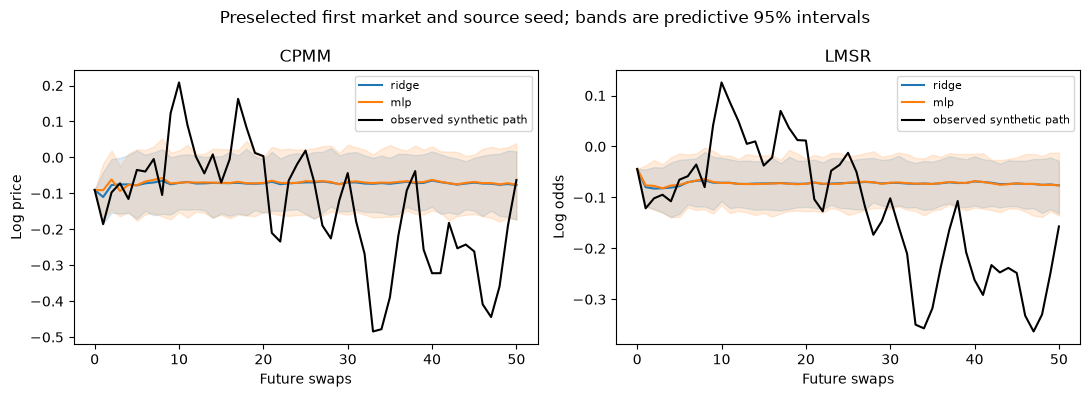

In [7]:
def batch_transition(mechanism, states, u, fee, b):
    magnitude=abs(u); before=states.copy()
    if mechanism=="CPMM":
        factor=1+(1-fee)*magnitude
        states=np.column_stack([np.where(u>=0,before[:,0]/factor,before[:,0]*(1+magnitude)),
                                np.where(u>=0,before[:,1]*(1+magnitude),before[:,1]/factor)])
        valid=np.isfinite(states).all(axis=1)&(states>0).all(axis=1)
        k0,k1=before.prod(axis=1),states.prod(axis=1)
        valid &= k1>=k0*(1-1e-10) if fee else np.isclose(k0,k1,rtol=1e-10,atol=1e-10)
        coords=np.log(states[:,1]/states[:,0])
    else:
        states=before+b*np.column_stack([np.maximum(-u,0),np.maximum(u,0)])
        coords=(states[:,1]-states[:,0])/b
        probability=1/(1+np.exp(-np.clip(coords,-700,700)))
        valid=np.isfinite(states).all(axis=1)&(probability>0)&(probability<1)
    return states,coords,valid

# Verify the fast path against the scalar mechanism equations before using it.
for mechanism,state in [("CPMM",(100.,150.)),("LMSR",(0.,0.))]:
    values=np.array([-.4,-.01,0.,.2])
    fast,_,valid=batch_transition(mechanism,np.tile(state,(4,1)),values,.003,100.)
    exact=np.array([transition(mechanism,state,float(v),.003,100.) for v in values])
    assert np.allclose(fast,exact) and valid.all()

def ensemble(model, path, start, horizon, seed):
    rng=np.random.default_rng(seed); X=path["X"] if "X" in path else dataset(path)[0]
    states=np.tile(path["states"][start],(CFG["draws"],1))
    buffers=np.repeat(X[start:start+1],CFG["draws"],axis=0)
    past=([0.]*4+list(path["u"][max(0,start-4):start]))[-4:]
    histories=np.tile(past,(CFG["draws"],1))
    reference,b,fee,mechanism=path["refs"][start],path["b"],path["fee"],path["m"]
    trajectories=[]; violations=0
    for _ in range(horizon):
        u=np.clip(model["predict"](buffers)+rng.normal(0,model["sigma"],len(states)),-FLOW_LIMIT,FLOW_LIMIT)
        states,coords,valid=batch_transition(mechanism,states,u,fee,b)
        violations+=int((~valid).sum()); trajectories.append(coords)
        histories=np.roll(histories,-1,axis=1); histories[:,-1]=u
        next_rows=np.column_stack([histories[:,-1],histories[:,-2],histories.mean(axis=1),histories.std(axis=1),
                                   reference-coords,np.zeros(len(states)),np.full(len(states),float(mechanism=="LMSR"))])
        buffers=np.concatenate([buffers[:,1:],next_rows[:,None]],axis=1)
    return np.array(trajectories).T,violations/(horizon*len(states))

def path_scores(samples, actual, initial, tail_threshold):
    last=np.sort(samples[:,-1]); n=len(last)
    crps=np.mean(abs(last-actual[-1]))-np.sum((2*np.arange(1,n+1)-n-1)*last)/n**2
    low,high=np.quantile(last,[.025,.975])
    paths=np.column_stack([np.full(n,initial),samples]); truth=np.r_[initial,actual]
    downward=(np.maximum.accumulate(paths,axis=1)-paths).max(axis=1)
    actual_downward=float((np.maximum.accumulate(truth)-truth).max())
    tail_probability=float(np.mean(last-initial < -tail_threshold)); tail_event=float(actual[-1]-initial < -tail_threshold)
    return dict(path_mean_rmse=float(np.sqrt(np.mean((samples.mean(axis=0)-actual)**2))),terminal_crps=float(crps),
                terminal_coverage95=float(low<=actual[-1]<=high),interval_width95=float(high-low),
                tail_threshold=tail_threshold,tail_probability=tail_probability,tail_event=tail_event,
                tail_brier=(tail_probability-tail_event)**2,
                downward_excursion_error=abs(float(downward.mean())-actual_downward))

# Independent small-array checks of CRPS, tail probability and path excursion.
check_samples=np.array([[.1,.2],[.2,-.3],[-.1,.4]])
check_scores=path_scores(check_samples,np.array([0.,.1]),0.,.25)
last=check_samples[:,-1]
brute_crps=np.mean(abs(last-.1))-.5*np.mean(abs(last[:,None]-last[None,:]))
assert np.isclose(check_scores["terminal_crps"],brute_crps)
assert np.isclose(check_scores["tail_brier"],1/9)
assert np.isclose(check_scores["downward_excursion_error"],.2)

path_rows=[]; illustrations={}
for mechanism in ("CPMM","LMSR"):
    for seed in CFG["seeds"]:
        for market in range(CFG["markets"]):
            path=make_path(mechanism,"reference",10000+market,depth=400.)
            for name,model in fitted[mechanism,"reference",seed].items():
                for horizon in HORIZONS:
                    start=LOOKBACK; initial=coordinate(mechanism,path["states"][start],path["b"])
                    samples,invalid=ensemble(model,path,start,horizon,seed+market)
                    actual=np.array([coordinate(mechanism,s,path["b"]) for s in path["states"][start+1:start+horizon+1]])
                    path_rows.append(dict(mechanism=mechanism,seed=seed,market=market,model=name,horizon=horizon,
                        violation_rate=invalid,**path_scores(samples,actual,initial,model["tail_scale"]*np.sqrt(horizon))))
                    if seed==CFG["seeds"][0] and market==0 and horizon==max(HORIZONS) and name in ("mlp","ridge"):
                        illustrations[mechanism,name]=(samples,actual,initial)
path_results=pd.DataFrame(path_rows)
display(path_results.groupby(["mechanism","horizon","model"])[
    ["path_mean_rmse","terminal_crps","terminal_coverage95","tail_brier","downward_excursion_error","violation_rate"]].mean().round(4))

fig,axes=plt.subplots(1,2,figsize=(11,4))
for axis,mechanism in zip(axes,("CPMM","LMSR")):
    for name,color in [("ridge","tab:blue"),("mlp","tab:orange")]:
        samples,actual,initial=illustrations[mechanism,name]; steps=np.arange(len(actual)+1)
        values=np.column_stack([np.full(len(samples),initial),samples]); low,high=np.quantile(values,[.025,.975],axis=0)
        axis.fill_between(steps,low,high,color=color,alpha=.14)
        axis.plot(steps,values.mean(axis=0),color=color,label=name)
    axis.plot(steps,np.r_[initial,actual],color="black",label="observed synthetic path")
    axis.set(title=mechanism,xlabel="Future swaps",ylabel="Log price" if mechanism=="CPMM" else "Log odds"); axis.legend(fontsize=8)
fig.suptitle("Preselected first market and source seed; bands are predictive 95% intervals")
plt.tight_layout(); fig.savefig(OUT/"path_ensembles.png",dpi=160); plt.show()


## 8. Paired comparisons and the two figures to interpret

Average across source training repeats within each target market before constructing the target-market paired interval; do not count every seed/model/budget row as an independent market. These small-sample Student t intervals are descriptive and conditional on the tested source repeats. They are not adjusted for multiple comparisons and do not replace source-uncertainty analysis. The final protocol must predeclare its primary contrast. Real-market uncertainty must instead use contiguous time blocks.


,mechanism,budget,reference,markets,delta,low,high
0,CPMM,0.10,shrinkage_mean,10,0.00008,-0.00498,0.00514
1,CPMM,0.10,source_mean_bias,10,0.00008,-0.00498,0.00514
2,CPMM,0.10,source_ridge_bias,10,0.00270,0.00192,0.00347
3,CPMM,0.10,target_ridge,10,-0.04772,-0.07611,-0.01932
4,CPMM,0.10,target_mlp,10,-0.02136,-0.02839,-0.01433
5,CPMM,0.25,shrinkage_mean,10,-0.00122,-0.00560,0.00316
6,CPMM,0.25,source_mean_bias,10,-0.00122,-0.00560,0.00316
7,CPMM,0.25,source_ridge_bias,10,0.00263,0.00187,0.00340
8,CPMM,0.25,target_ridge,10,-0.00067,-0.00354,0.00220
9,CPMM,0.25,target_mlp,10,-0.00842,-0.01185,-0.00498


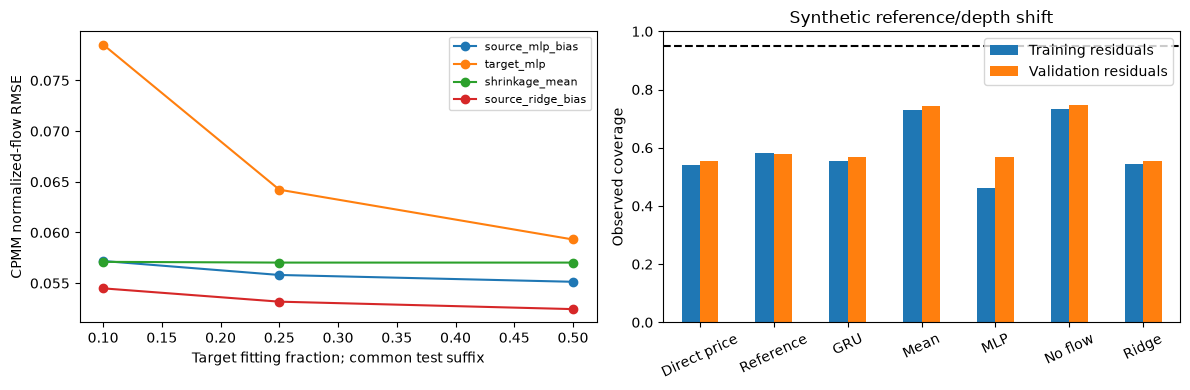

,mechanism,regime,model,mean_rmse,market_se,source_sd,markets,source_repeats
0,CPMM,nonlinear,direct_coordinate_ridge,0.04805,0.00063,0.00011,10,3
1,CPMM,nonlinear,external,0.06047,0.00072,0.00023,10,3
2,CPMM,nonlinear,gru,0.04553,0.00057,0.00050,10,3
3,CPMM,nonlinear,mean,0.06155,0.00067,0.00049,10,3
4,CPMM,nonlinear,mlp,0.04967,0.00055,0.00081,10,3
5,CPMM,nonlinear,no_flow,0.06033,0.00072,0.00000,10,3
6,CPMM,nonlinear,ridge,0.04776,0.00062,0.00009,10,3
7,CPMM,null_noise,direct_coordinate_ridge,0.04458,0.00045,0.00018,10,3
8,CPMM,null_noise,external,0.04435,0.00045,0.00020,10,3
9,CPMM,null_noise,gru,0.04439,0.00042,0.00009,10,3


,mechanism,regime,challenger,reference,metric,markets,delta,low,high
0,CPMM,nonlinear,mlp,no_flow,rmse,10,-0.01067,-0.01158,-0.00975
1,CPMM,nonlinear,mlp,ridge,rmse,10,0.00191,0.00098,0.00283
2,CPMM,nonlinear,mlp,external,rmse,10,-0.01080,-0.01215,-0.00945
3,CPMM,nonlinear,mlp,gru,rmse,10,0.00414,0.00324,0.00504
4,CPMM,null_noise,mlp,no_flow,rmse,10,0.00585,0.00441,0.00729
5,CPMM,null_noise,mlp,ridge,rmse,10,0.00543,0.00424,0.00661
6,CPMM,null_noise,mlp,external,rmse,10,0.00566,0.00435,0.00697
7,CPMM,null_noise,mlp,gru,rmse,10,0.00562,0.00434,0.00691
8,CPMM,reference,mlp,no_flow,rmse,10,-0.00106,-0.00305,0.00094
9,CPMM,reference,mlp,ridge,rmse,10,0.00296,0.00250,0.00341


,mechanism,horizon,challenger,reference,metric,markets,delta,low,high
0,CPMM,10,mlp,no_flow,terminal_crps,10,0.01590,-0.03588,0.06767
1,CPMM,10,mlp,ridge,terminal_crps,10,-0.00268,-0.00437,-0.00100
2,CPMM,10,mlp,direct_coordinate_ridge,terminal_crps,10,-0.00264,-0.00432,-0.00095
3,CPMM,10,mlp,gru,terminal_crps,10,-0.00515,-0.00813,-0.00218
4,CPMM,50,mlp,no_flow,terminal_crps,10,-0.04211,-0.08581,0.00159
5,CPMM,50,mlp,ridge,terminal_crps,10,-0.00126,-0.00269,0.00016
6,CPMM,50,mlp,direct_coordinate_ridge,terminal_crps,10,-0.00123,-0.00263,0.00017
7,CPMM,50,mlp,gru,terminal_crps,10,-0.00150,-0.00450,0.00149
8,LMSR,10,mlp,no_flow,terminal_crps,10,0.00368,-0.02535,0.03271
9,LMSR,10,mlp,ridge,terminal_crps,10,-0.00132,-0.00269,0.00005


,,n_fit,n_validation,mean_parameters
model,estimator,,,
direct_coordinate_ridge,ridge,576,384,29
external,external,576,384,3
gru,gru,576,384,769
mean,mean,576,384,1
mlp,mlp,576,384,481
no_flow,no_flow,576,384,0
ridge,ridge,576,384,29


In [8]:
paired_rows = []
for mechanism in ("CPMM", "LMSR"):
    for budget in (0.1, 0.25, 0.5):
        table = adapt_results.query("mechanism == @mechanism and budget == @budget").groupby(
            ["market", "model"])["rmse"].mean().unstack()
        for reference in ("shrinkage_mean", "source_mean_bias", "source_ridge_bias", "target_ridge", "target_mlp"):
            d = table["source_mlp_bias"]-table[reference]
            half = t.ppf(0.975, len(d)-1)*d.std(ddof=1)/np.sqrt(len(d))
            paired_rows.append(dict(mechanism=mechanism, budget=budget, reference=reference,
                                    markets=len(d), delta=d.mean(), low=d.mean()-half, high=d.mean()+half))
paired_results = pd.DataFrame(paired_rows)
display(paired_results.round(5))
MODEL_LABELS={"direct_coordinate_ridge":"Direct price","external":"Reference","gru":"GRU",
              "mean":"Mean","mlp":"MLP","no_flow":"No flow","ridge":"Ridge"}
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for name in ("source_mlp_bias", "target_mlp", "shrinkage_mean", "source_ridge_bias"):
    curve = adapt_results.query("mechanism == 'CPMM' and model == @name").groupby("budget")["rmse"].mean()
    axes[0].plot(curve.index, curve.values, marker="o", label=name)
axes[0].set(xlabel="Target fitting fraction; common test suffix", ylabel="CPMM normalized-flow RMSE")
axes[0].legend(fontsize=8)
coverage = flow_results.query("regime == 'reference'").groupby("model")[["raw_coverage95", "validation_coverage95"]].mean()
coverage=coverage.rename(index=MODEL_LABELS,columns={"raw_coverage95":"Training residuals","validation_coverage95":"Validation residuals"})
coverage.plot.bar(ax=axes[1],rot=25); axes[1].axhline(.95, color="black", linestyle="--")
axes[1].set_xlabel("")
axes[1].set(ylabel="Observed coverage", ylim=(0,1), title="Synthetic reference/depth shift")
plt.tight_layout(); fig.savefig(OUT/"adaptation_and_calibration.png", dpi=160)
plt.show()

def paired_market_contrast(table,challenger,reference,metric,**labels):
    means=table.groupby(["market","model"])[metric].mean().unstack()
    delta=(means[challenger]-means[reference]).dropna()
    half=t.ppf(.975,len(delta)-1)*delta.std(ddof=1)/np.sqrt(len(delta))
    return dict(labels,challenger=challenger,reference=reference,metric=metric,markets=len(delta),
                delta=delta.mean(),low=delta.mean()-half,high=delta.mean()+half)

flow_pairs=[]; path_pairs=[]; flow_summary_rows=[]
for (mechanism,regime),table in flow_results.groupby(["mechanism","regime"]):
    for reference in ("no_flow","ridge","external","gru"):
        flow_pairs.append(paired_market_contrast(table,"mlp",reference,"rmse",mechanism=mechanism,regime=regime))
    for name,values in table.groupby("model"):
        markets=values.groupby("market").rmse.mean(); sources=values.groupby("seed").rmse.mean()
        flow_summary_rows.append(dict(mechanism=mechanism,regime=regime,model=name,mean_rmse=markets.mean(),
             market_se=markets.std(ddof=1)/np.sqrt(len(markets)),source_sd=sources.std(ddof=1),
             markets=len(markets),source_repeats=len(sources)))
for (mechanism,horizon),table in path_results.groupby(["mechanism","horizon"]):
    for reference in ("no_flow","ridge","direct_coordinate_ridge","gru"):
        path_pairs.append(paired_market_contrast(table,"mlp",reference,"terminal_crps",mechanism=mechanism,horizon=horizon))
flow_paired=pd.DataFrame(flow_pairs); path_paired=pd.DataFrame(path_pairs); flow_summary=pd.DataFrame(flow_summary_rows)
training_diagnostics=pd.DataFrame(training_rows)
display(flow_summary.round(5)); display(flow_paired.round(5)); display(path_paired.round(5))
display(training_diagnostics.groupby(["model","estimator"])[["n_fit","n_validation","mean_parameters"]].first())


## 9. Real data: load a reconciled export and freeze time splits

Run `prepare_real_data.ipynb` first, or provide its documented equivalent export in `real_data/uniswap_v2_usdc_weth_2024_8weeks/`. Required artifacts are `model_events.csv`, `dataset_card.json`, `reference_prices.csv` and `checksums.json`. The main study imports no code from that notebook. Set `AMM_DATA_DIR` to choose another dataset directory. The card must label data as `real_market` or `synthetic_fixture`; fixture outputs are saved in a separate `fixture_pipeline_check` directory and never treated as real empirical evidence.

The loader checks source hashes, reference availability, finite values, flow normalization and state continuity. Complete blocks are assigned to chronological 60/20/20 fitting, validation and test periods. Histories are formed before slicing, so a test event can use its already-observed past. Model fitting and selection cannot use the test targets. The selected window, exclusion rules and primary comparison (full-information MLP versus full-information ridge) must be fixed before the final run.

The real fitting budget is frozen before viewing test results: at most 4,096 evenly spaced chronological fitting observations and 2,048 validation observations, with all test events scored. Sequence histories remain causal. These budgets count fitting labels; feature construction still uses the observed historical swaps. The one-second reference delay is a declared availability assumption rather than a measurement of actual publication latency. Three seeds, a 16-unit MLP and a 12-unit GRU (50 real-data epochs) keep this a small CPU experiment. Full and AMM-only estimators share these samples. See `paper/real_data_protocol.md` for acquisition, exclusion, sampling and claim scope.


In [9]:
def load_market_paths(directory):
    directory=Path(directory); meta=json.loads((directory/"dataset_card.json").read_text())
    if meta.get("data_kind") not in ("real_market","synthetic_fixture"): raise ValueError("Dataset kind is required")
    if meta.get("quote_symbol")!=meta.get("reference_quote_symbol"): raise ValueError("Reference quote mismatch")
    if meta.get("fee")!=.003 or int(meta["base_token_index"]) not in (0,1): raise ValueError("Unsupported pool metadata")
    hashes=json.loads((directory/"checksums.json").read_text())
    for name in ("model_events.csv","dataset_card.json","reference_prices.csv"):
        if name not in hashes or hashlib.sha256((directory/name).read_bytes()).hexdigest()!=hashes[name]:
            raise ValueError(f"Input checksum failed: {name}")
    frame=pd.read_csv(directory/"model_events.csv")
    columns=["timestamp","origin_timestamp","block_number","transaction_index","log_index","segment",
             "state_a_before","state_b_before","state_a_after","state_b_after","flow",
             "reference_coordinate","reference_return","reference_available_at"]
    if not set(columns).issubset(frame) or frame.empty: raise ValueError("Missing model events")
    if not np.isfinite(frame[columns].to_numpy(dtype=float)).all(): raise ValueError("Nonfinite model data")
    keys=["block_number","transaction_index","log_index"]
    if frame.duplicated(keys).any(): raise ValueError("Duplicate model events")
    frame=frame.sort_values(keys).reset_index(drop=True)
    if not frame.timestamp.is_monotonic_increasing: raise ValueError("Nonmonotone event time")
    if (frame.origin_timestamp>frame.timestamp).any() or (frame.reference_available_at>=frame.origin_timestamp).any():
        raise ValueError("Future event/reference information")
    if ((frame.origin_timestamp-frame.reference_available_at)>300).any(): raise ValueError("Stale reference")
    states=["state_a_before","state_b_before","state_a_after","state_b_after"]
    if (frame[states]<=0).any().any(): raise ValueError("Invalid reserves")
    observed=np.where(frame.flow>=0,(frame.state_b_after-frame.state_b_before)/frame.state_b_before,
                      -(frame.state_a_after-frame.state_a_before)/frame.state_a_before)
    if not np.allclose(observed,frame.flow,rtol=1e-8,atol=1e-12): raise ValueError("Inconsistent normalized flow")
    paths=[]
    for segment,group in frame.groupby("segment",sort=False):
        before=group[["state_a_before","state_b_before"]].to_numpy(); after=group[["state_a_after","state_b_after"]].to_numpy()
        if not np.allclose(before[1:],after[:-1],rtol=1e-12,atol=1e-12): raise ValueError("State gap within segment")
        if (group.origin_timestamp.to_numpy()[1:]<group.timestamp.to_numpy()[:-1]).any(): raise ValueError("Unobserved origin state")
        p=dict(m="CPMM",states=np.vstack([before[:1],after]),u=group.flow.to_numpy(),refs=group.reference_coordinate.to_numpy(),
               ref_returns=group.reference_return.to_numpy(),b=1.,fee=meta["fee"],market=int(segment),
               blocks=group.block_number.to_numpy(),times=group.timestamp.to_numpy())
        p["X"]=dataset(p)[0]; paths.append(p)
    return meta,frame,paths

def period_arrays(paths, lower=None, upper=None):
    items=[]
    for p in paths:
        mask=np.ones(len(p["u"]),dtype=bool)
        if lower is not None: mask &= p["blocks"]>=lower
        if upper is not None: mask &= p["blocks"]<upper
        if mask.any():
            dy=np.diff([coordinate(p["m"],s,p["b"]) for s in p["states"]])
            items.append((p["X"][mask],p["u"][mask],dy[mask],p["times"][mask]))
    if not items: raise ValueError("Empty chronological period")
    return tuple(np.concatenate([item[j] for item in items]) for j in range(4))

def inputs_for(X, reference=True):
    result=X.copy()
    if not reference: result[:,:,4:6]=0.
    return result

def model_with_inputs(model, reference=True):
    return dict(model,predict=lambda a: model["predict"](inputs_for(a,reference)))

def daily_flow_rows(estimator, X, y, times, **labels):
    days=(times//86400).astype(int); rows=[]
    for day in np.unique(days):
        mask=days==day
        rows.append(dict(labels,day=int(day),events=int(mask.sum()),**flow_scores(estimator,X[mask],y[mask])))
    return rows

real_flow_rows,real_daily_rows,real_adapt_rows,real_path_rows=[],[],[],[]
real_training_rows=[]
real_models={}; REAL_STATUS="PENDING_DATA: real-study code is present; no dataset supplied"
if (DATA_DIR/"dataset_card.json").exists():
    real_meta,real_frame,real_paths=load_market_paths(DATA_DIR)
    kind=real_meta["data_kind"]; REAL_STATUS=f"EVALUATING_{kind.upper()}"
    REAL_OUT=OUT/("fixture_pipeline_check" if kind=="synthetic_fixture" else "real_market")
    REAL_OUT.mkdir(parents=True,exist_ok=True)
    blocks=np.sort(real_frame.block_number.unique())
    if len(blocks)<20: raise ValueError("Need at least 20 distinct blocks for this declared split")
    train_end,test_start=blocks[int(.6*len(blocks))],blocks[int(.8*len(blocks))]
    RX,ry,rdy,rt=period_arrays(real_paths,upper=train_end)
    RV,rz,rdz,vt=period_arrays(real_paths,lower=train_end,upper=test_start)
    TX,ty,tdy,tt=period_arrays(real_paths,lower=test_start)
    total_train,total_validation=len(ry),len(rz)
    fit_indices=np.linspace(0,len(ry)-1,min(REAL_FIT_CAP,len(ry)),dtype=int)
    validation_indices=np.linspace(0,len(rz)-1,min(REAL_VALIDATION_CAP,len(rz)),dtype=int)
    RX,ry,rdy,rt=(a[fit_indices] for a in (RX,ry,rdy,rt))
    RV,rz,rdz,vt=(a[validation_indices] for a in (RV,rz,rdz,vt))
    real_split=dict(train_end_block=int(train_end),test_start_block=int(test_start),
                    n_train_available=total_train,n_validation_available=total_validation,
                    fitting_indices_sha256=hashlib.sha256(fit_indices.tobytes()).hexdigest(),
                    validation_indices_sha256=hashlib.sha256(validation_indices.tobytes()).hexdigest(),
                    fitting_first_utc=pd.Timestamp(rt.min(),unit="s",tz="UTC").isoformat(),
                    fitting_last_utc=pd.Timestamp(rt.max(),unit="s",tz="UTC").isoformat(),
                    validation_first_utc=pd.Timestamp(vt.min(),unit="s",tz="UTC").isoformat(),
                    test_first_utc=pd.Timestamp(tt.min(),unit="s",tz="UTC").isoformat(),
                    test_last_utc=pd.Timestamp(tt.max(),unit="s",tz="UTC").isoformat(),
                    real_gru_epochs=REAL_EPOCHS,
                    n_train=len(ry),n_validation=len(rz),n_test=len(ty),data_kind=kind,
                    above_declared_flow_limit=int((abs(real_frame.flow)>FLOW_LIMIT).sum()))
    (REAL_OUT/"split.json").write_text(json.dumps(real_split,indent=2))
    for seed in CFG["seeds"]:
        for use_reference in (True,False):
            names=MODEL_NAMES if use_reference else ("ridge","mlp","gru")
            bundle=make_bundle(inputs_for(RX,use_reference),ry,inputs_for(RV,use_reference),rz,
                               seed,"CPMM",rdy,rdz,names=names,fee=real_meta["fee"],epochs=REAL_EPOCHS)
            for name,base in bundle.items():
                label=("full_" if use_reference else "amm_only_")+name
                model=model_with_inputs(base,use_reference); real_models[seed,label]=model
                real_training_rows.append(dict(task="full_fit",data_kind=kind,seed=seed,model=label,**base["diagnostic"]))
                real_flow_rows.append(dict(data_kind=kind,seed=seed,model=label,n_fit=len(ry),n_validation=len(rz),
                                           **flow_scores(model,TX,ty)))
                real_daily_rows+=daily_flow_rows(model,TX,ty,tt,data_kind=kind,seed=seed,model=label)
    display(pd.DataFrame(real_flow_rows).groupby("model")[["rmse","mse_skill","validation_coverage95"]].mean())
else:
    print(REAL_STATUS)


,rmse,mse_skill,validation_coverage95
model,,,
amm_only_gru,0.000130,-0.174670,0.982346
amm_only_mlp,0.000129,-0.163613,0.976298
amm_only_ridge,0.000131,-0.193561,0.971988
full_direct_coordinate_ridge,0.000129,-0.170178,0.974181
full_external,0.000118,0.023481,0.988205
full_gru,0.000125,-0.086612,0.985408
full_mean,0.000120,0.000019,0.985711
full_mlp,0.000132,-0.217452,0.969732
full_no_flow,0.000120,0.000000,0.985711


## 10. Real target-data efficiency and autonomous paths

For adaptation, 0/10/25/50% denotes a time-ordered prefix of the shared capped fitting sample, while every estimator is scored on the identical final test period. Real-only prefix models receive no additional validation labels: ridge regularization is frozen from source validation, neural architecture/epoch budgets are fixed, and any prefix checkpoint selection sees only that prefix. The intervening validation-period labels are not used to fit these prefix models. They may be observed as past history when a later one-step forecast is made. Weights remain frozen in the explicitly named source-plus-bias models.

Main real path forecasts use the full fitting/validation models above, one preselected first eligible origin per calendar day, and 10/50 future swaps confined to a single uninterrupted segment in the test period. External prices are held at the origin. Every model uses the same origins and stochastic seeds. This measures event-count predictive distributions conditional on the retained uninterrupted segments. Consecutive swaps can occur in the same block: log order defines historical event-index conditioning, while all logs become publicly observable after block publication. This does not imply an observer could trade between those swaps before publication.


In [10]:
real_examples={}
if real_models:
    order=np.argsort(rt,kind="stable"); AX,ay=RX[order],ry[order]
    for seed in CFG["seeds"]:
        source=fitted["CPMM","reference",seed]
        for fraction in (0.,.1,.25,.5):
            count=int(len(ay)*fraction)
            models={"no_flow":source["no_flow"],"source_ridge":source["ridge"],
                    "source_mlp":source["mlp"],"source_gru":source["gru"]}
            if count:
                px,py=AX[:count],ay[:count]
                for name in ("mean","ridge","mlp","gru"):
                    models[f"source_{name}_bias"]=adapted(source[name],px,py)
                for name in ("mean","ridge","mlp","gru"):
                    models[f"target_{name}"]=fit_model(name,px,py,px,py,seed,
                                                       alpha=source["ridge"]["alpha"] if name=="ridge" else None,epochs=REAL_EPOCHS)
                    real_training_rows.append(dict(task="adaptation",data_kind=kind,seed=seed,budget=fraction,
                        model=f"target_{name}",**models[f"target_{name}"]["diagnostic"]))
                value=float(py.sum()/(count+5))
                models["shrinkage_mean"]=dict(source["mean"],predict=lambda a,v=value:np.full(len(a),v))
            for name,model in models.items():
                for row in daily_flow_rows(model,TX,ty,tt,data_kind=kind,seed=seed,model=name,budget=fraction,n_target_available=count,
                        n_target_fit=0 if name in ("no_flow","source_ridge","source_mlp","source_gru") else count):
                    real_adapt_rows.append({k:v for k,v in row.items() if k in
                        ["data_kind","seed","model","budget","n_target_available","n_target_fit","day","events","rmse","mse_skill"]})
    origins=[]; used_days=set()
    for p in real_paths:
        for start in range(LOOKBACK,len(p["u"])-max(HORIZONS)+1):
            day=int(p["times"][start]//86400)
            if p["blocks"][start]>=test_start and day not in used_days:
                origins.append((p,start,day)); used_days.add(day)
    if not origins: raise ValueError("No admissible real path origins; inspect segment coverage")
    for (seed,label),model in real_models.items():
        for p,start,day in origins:
            for horizon in HORIZONS:
                samples,invalid=ensemble(model,p,start,horizon,seed+day)
                actual=np.array([coordinate("CPMM",s) for s in p["states"][start+1:start+horizon+1]])
                if seed==CFG["seeds"][0] and day==origins[0][2] and horizon==max(HORIZONS) and label in ("full_mlp","full_ridge"):
                    real_examples[label]=(samples,actual,coordinate("CPMM",p["states"][start]))
                real_path_rows.append(dict(data_kind=kind,seed=seed,model=label,day=day,horizon=horizon,
                                           violation_rate=invalid,**path_scores(samples,actual,coordinate("CPMM",p["states"][start]),
                                                                                  model["tail_scale"]*np.sqrt(horizon))))
    REAL_STATUS=f"COMPLETED_{kind.upper()}_PIPELINE; actual market evidence only when data_kind=real_market"
    display(pd.DataFrame(real_path_rows).groupby(["horizon","model"])[
        ["terminal_crps","terminal_coverage95","path_mean_rmse","violation_rate"]].mean())


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


/workspace/.venv-notebooks/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


terminal_crps  terminal_coverage95  \
horizon model                                                              
10      amm_only_gru                       0.000910             1.000000   
        amm_only_mlp                       0.000629             1.000000   
        amm_only_ridge                     0.000331             0.900000   
        full_direct_coordinate_ridge       0.000322             0.900000   
        full_external                      0.000480             1.000000   
        full_gru                           0.000490             1.000000   
        full_mean                          0.000478             1.000000   
        full_mlp                           0.000496             1.000000   
        full_no_flow                       0.000478             1.000000   
        full_ridge                         0.000322             0.900000   
50      amm_only_gru                       0.012622             0.366667   
        amm_only_mlp                       0.002939             0.866667   
        amm_only_ridge                     0.001003             0.900000   
        full_direct_coordinate_ridge       0.000925             0.900000   
        full_external                      0.001082             0.900000   
        full_gru                           0.001477             0.933333   
        full_mean                          0.001159             1.000000   
        full_mlp                           0.001803             0.933333   
        full_no_flow                       0.001158             1.000000   
        full_ridge                         0.000926             0.900000   

                                      path_mean_rmse  violation_rate  
horizon model                                                         
10      amm_only_gru                        0.000764             0.0  
        amm_only_mlp                        0.000497             0.0  
        amm_only_ridge                      0.000322             0.0  
        full_direct_coordinate_ridge        0.000326             0.0  
        full_external                       0.000466             0.0  
        full_gru                            0.000422             0.0  
        full_mean                           0.000345             0.0  
        full_mlp                            0.000497             0.0  
        full_no_flow                        0.000345             0.0  
        full_ridge                          0.000326             0.0  
50      amm_only_gru                        0.009156             0.0  
        amm_only_mlp                        0.002256             0.0  
        amm_only_ridge                      0.000889             0.0  
        full_direct_coordinate_ridge        0.000845             0.0  
        full_external                       0.001076             0.0  
        full_gru                            0.001422             0.0  
        full_mean                           0.000865             0.0  
        full_mlp                            0.001617             0.0  
        full_no_flow                        0.000865             0.0  
        full_ridge                          0.000845             0.0

## 11. Dependence-aware uncertainty and real evidence export

The primary real contrast is full-information MLP versus full-information ridge on daily flow RMSE. Secondary contrasts compare adapted MLP with shrinkage, source-mean adaptation, source-ridge adaptation and real-only models. Average training repeats within a day, then resample three consecutive calendar days with a circular moving-block bootstrap. Missing calendar days remain missing rather than making distant days adjacent. Intervals require at least six observed days and are descriptive, conditional on the selected period and training repeats; there is no multiple-testing-adjusted discovery claim. Retain source-seed variation separately. Apply the same method to terminal CRPS at each horizon.


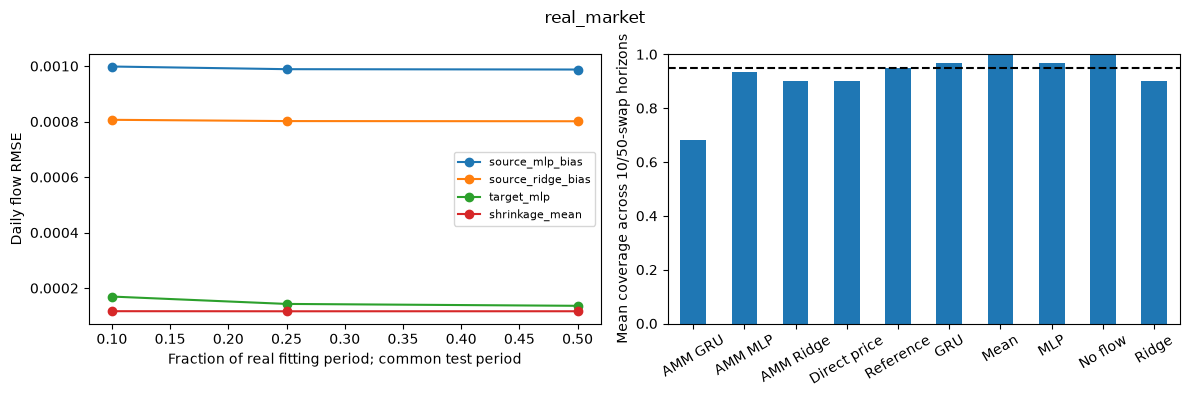

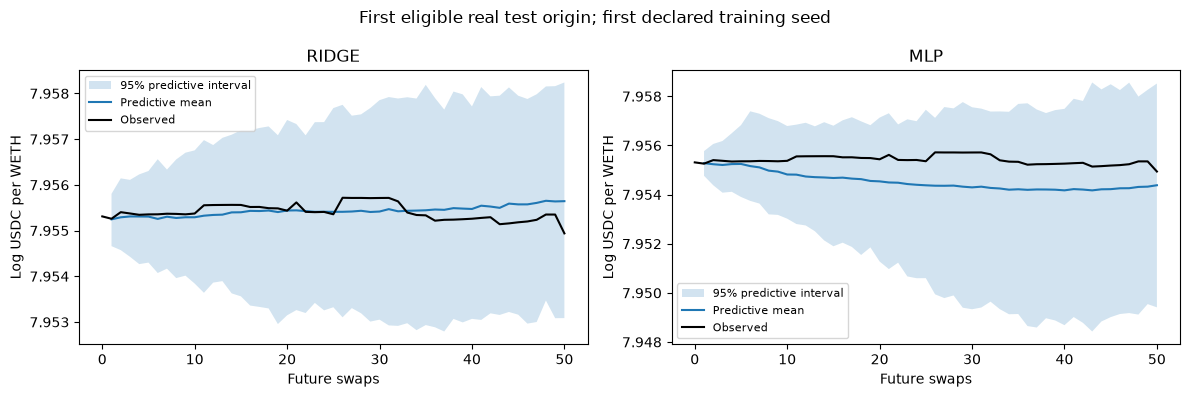

,task,data_kind,challenger,reference,metric,delta,low,high,days,budget,horizon
0,flow,real_market,full_mlp,full_ridge,rmse,0.000003,0.000002,3.735008e-06,10,NaN,NaN
1,flow,real_market,full_mlp,full_no_flow,rmse,0.000012,0.000011,1.338408e-05,10,NaN,NaN
2,flow,real_market,full_mlp,full_external,rmse,0.000014,0.000011,1.547650e-05,10,NaN,NaN
3,flow,real_market,full_gru,full_ridge,rmse,-0.000005,-0.000006,-3.276895e-06,10,NaN,NaN
4,flow,real_market,full_gru,full_no_flow,rmse,0.000005,0.000004,6.446494e-06,10,NaN,NaN
5,flow,real_market,full_ridge,amm_only_ridge,rmse,-0.000001,-0.000002,-5.554756e-08,10,NaN,NaN
6,flow,real_market,full_mlp,amm_only_mlp,rmse,0.000003,0.000002,3.648832e-06,10,NaN,NaN
7,flow,real_market,full_gru,amm_only_gru,rmse,-0.000005,-0.000006,-3.880111e-06,10,NaN,NaN
8,adaptation,real_market,source_mlp_bias,shrinkage_mean,rmse,0.000882,0.000867,8.968056e-04,10,0.10,NaN
9,adaptation,real_market,source_mlp_bias,source_mean_bias,rmse,0.000881,0.000867,8.966333e-04,10,0.10,NaN


COMPLETED_REAL_MARKET_PIPELINE; actual market evidence only when data_kind=real_market


In [11]:
def block_interval(day_to_difference, block_days=3, repeats=1000, seed=901):
    clean={int(k):float(v) for k,v in day_to_difference.items() if math.isfinite(v)}
    if not clean: return dict(delta=float("nan"),low=float("nan"),high=float("nan"),days=0)
    mean=statistics.mean(clean.values())
    if len(clean)<6: return dict(delta=mean,low=float("nan"),high=float("nan"),days=len(clean))
    days=list(range(min(clean),max(clean)+1)); rng=random.Random(seed); draws=[]
    for _ in range(repeats):
        indices=[]
        while len(indices)<len(days):
            start=rng.randrange(len(days)); indices.extend((start+j)%len(days) for j in range(block_days))
        values=[clean[days[i]] for i in indices[:len(days)] if days[i] in clean]
        if values: draws.append(statistics.mean(values))
    draws.sort()
    def quantile(p):
        index=p*(len(draws)-1); j=int(index)
        return draws[j]+(draws[min(j+1,len(draws)-1)]-draws[j])*(index-j)
    return dict(delta=mean,low=quantile(.025),high=quantile(.975),days=len(clean))

def real_contrast(table,challenger,reference,metric="rmse",**labels):
    means=table.groupby(["day","model"])[metric].mean().unstack()
    if challenger not in means or reference not in means: return None
    differences=(means[challenger]-means[reference]).dropna()
    return dict(labels,challenger=challenger,reference=reference,metric=metric,
                **block_interval(differences.to_dict(),CALENDAR_BLOCK_DAYS,BOOTSTRAP_REPEATS))

real_paired_rows=[]
if real_models:
    daily=pd.DataFrame(real_daily_rows); adaptation=pd.DataFrame(real_adapt_rows); paths_table=pd.DataFrame(real_path_rows)
    for challenger,reference in [("full_mlp","full_ridge"),("full_mlp","full_no_flow"),
            ("full_mlp","full_external"),("full_gru","full_ridge"),("full_gru","full_no_flow"),
            ("full_ridge","amm_only_ridge"),("full_mlp","amm_only_mlp"),("full_gru","amm_only_gru")]:
        real_paired_rows.append(real_contrast(daily,challenger,reference,task="flow",data_kind=kind))
    for budget in (.1,.25,.5):
        table=adaptation.query("budget == @budget")
        for reference in ("shrinkage_mean","source_mean_bias","source_ridge_bias","target_ridge","target_mlp","target_gru"):
            real_paired_rows.append(real_contrast(table,"source_mlp_bias",reference,task="adaptation",budget=budget,data_kind=kind))
    for horizon in HORIZONS:
        real_paired_rows.append(real_contrast(paths_table.query("horizon == @horizon"),"full_mlp","full_ridge",
                                             metric="terminal_crps",task="paths",horizon=horizon,data_kind=kind))
    for name,rows in [("flow",real_flow_rows),("daily_flow",real_daily_rows),("adaptation",real_adapt_rows),
                      ("paths",real_path_rows),("training_diagnostics",real_training_rows),("paired",[r for r in real_paired_rows if r])]:
        pd.DataFrame(rows).to_csv(REAL_OUT/f"{name}.csv",index=False)
    pd.DataFrame(real_flow_rows).groupby("model").rmse.agg(mean_rmse="mean",source_sd="std").to_csv(REAL_OUT/"flow_summary.csv")
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name in ("source_mlp_bias","source_ridge_bias","target_mlp","shrinkage_mean"):
        curve=adaptation.query("model == @name").groupby("budget").rmse.mean()
        axes[0].plot(curve.index,curve,marker="o",label=name)
    axes[0].set(xlabel="Fraction of real fitting period; common test period",ylabel="Daily flow RMSE")
    axes[0].legend(fontsize=8)
    labels={name:("AMM " if name.startswith("amm_only_") else "")+MODEL_LABELS[name.removeprefix("full_").removeprefix("amm_only_")]
            for name in paths_table.model.unique()}
    paths_table.groupby("model").terminal_coverage95.mean().rename(index=labels).plot.bar(ax=axes[1],rot=30)
    axes[1].set_xlabel("")
    axes[1].axhline(.95,color="black",linestyle="--"); axes[1].set(ylabel="Mean coverage across 10/50-swap horizons",ylim=(0,1))
    fig.suptitle(kind); plt.tight_layout(); fig.savefig(REAL_OUT/"adaptation_and_calibration.png",dpi=160); plt.show()
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,(label,(samples,actual,origin)) in zip(axes,real_examples.items()):
        x=np.arange(1,samples.shape[1]+1); low,high=np.quantile(samples,[.025,.975],axis=0)
        ax.fill_between(x,low,high,alpha=.2,label="95% predictive interval")
        ax.plot(x,samples.mean(axis=0),label="Predictive mean")
        ax.plot(np.arange(len(actual)+1),np.r_[origin,actual],color="black",label="Observed")
        ax.set(title=label.removeprefix("full_").upper(),xlabel="Future swaps",ylabel="Log USDC per WETH"); ax.legend(fontsize=8)
    fig.suptitle("First eligible real test origin; first declared training seed")
    plt.tight_layout(); fig.savefig(REAL_OUT/"path_ensembles.png",dpi=160); plt.show()
    display(pd.DataFrame([r for r in real_paired_rows if r]))
print(REAL_STATUS)


## 12. Export evidence and write the conclusions

**Recorded final run:** 126,934 reconciled swaps (98.18% of 129,289), 26,453 untouched test events, ten test calendar days, three training repeats and 600 real path evaluations. The complete synthetic-plus-real study ran in 51.46 seconds on CPU.

- **Structure:** zero measured violations in all real and synthetic path rows. This is the shared mechanism map's property, also available to the direct-coordinate comparator.
- **Real one-step forecasting:** the simple reference-gap ridge has the best point score in the declared set, about 2.35% lower MSE than no flow. Full MLP does worse than ridge/no flow; GRU improves on full ridge but remains worse than no flow. Neural superiority is unsupported here.
- **Adaptation:** source MLP plus bias remains about 8.5 times the shrinkage-mean daily RMSE at 2,048 target fitting labels. This frozen synthetic pretraining/bias-adapter protocol does not establish real target-data efficiency.
- **Paths:** ridge/direct-coordinate ridge have stronger terminal CRPS than MLP in this window. MLP-minus-ridge CRPS is worse with a descriptive interval above zero at 10 swaps; the 50-swap interval crosses zero. Ten origins provide limited calibration/tail evidence.

All controls and failed cases remain exported. Validity, forecast accuracy, calibration and adaptation are separate claims. The supported contribution is a compact, reproducible mechanism-aware benchmark with exact event reconciliation and strong simple controls. The code/scientific tasks are complete. The full writeup is delivered in `paper/report/capstone_report.pdf`; presentation preparation remains. The paper phase reuses these outcomes without requiring a favorable new discovery.

The submission evidence comprises the executed notebook, frozen dataset card and source query, reconciliation/coverage reports, result tables and figures, package versions and hashes. Inspect the exported real execution status and all negative controls before interpreting calibration or adaptation. The direct-coordinate ridge above is a fitted comparator that shares the mechanism map; do not describe its validity as an unconstrained-state comparison. Cross-mechanism zero-shot superiority and a learned-diffusion claim are outside this notebook's current scope. The paper should reuse the completed capstone's data, experiments, proposition, and figures; later work is manuscript adaptation, related-work positioning, reproducibility checking, and submission. A reviewer can still request an additional experiment.


In [12]:
for name, table in [("flow", flow_results), ("adaptation", adapt_results),
                    ("paths", path_results), ("paired", paired_results), ("flow_paired",flow_paired),
                    ("path_paired",path_paired),("flow_summary",flow_summary),("training_diagnostics",training_diagnostics)]:
    table.to_csv(OUT/f"{name}.csv", index=False)
inputs = {name: hashlib.sha256((DATA_DIR/name).read_bytes()).hexdigest()
          for name in ("model_events.csv", "dataset_card.json", "reference_prices.csv", "checksums.json") if (DATA_DIR/name).exists()}
manifest = dict(profile=PROFILE, config=CFG, lookback=LOOKBACK, flow_limit=FLOW_LIMIT,
                horizons=HORIZONS, models=MODEL_NAMES, real_status=REAL_STATUS, input_hashes=inputs,
                python=platform.python_version(),
                packages={p: importlib.metadata.version(p) for p in
                          ("numpy", "pandas", "matplotlib", "scipy", "scikit-learn", "torch")},
                protocol="compact_notebook_v4; frozen small real-data budget; actual market evidence requires data",
                frozen_protocol_sha256=hashlib.sha256((OUT/"protocol.json").read_bytes()).hexdigest(),
                calendar_block_days=CALENDAR_BLOCK_DAYS,bootstrap_repeats=BOOTSTRAP_REPEATS)
from IPython import get_ipython
manifest["executed_code_sha256"]=hashlib.sha256("\n\n".join(get_ipython().history_manager.input_hist_raw[1:]).encode()).hexdigest()
(OUT/"manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved", OUT.resolve())


Saved /workspace/notebook_results/final
